# Más allá: la definición de incumplimiento es parte de la PD, los retiros informativos y las cohortes delgadas

- **Nivel:** 4, Más allá del estado del arte
- **Requisitos previos:** los cuadernos 01, 02 y 07 de este tema (la PD por grado, los intervalos y la función IRB)
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este cuaderno puedes:

- mostrar con los datos de una agencia que la definición de incumplimiento es parte de la PD: el mismo grado tiene dos PD de largo plazo a un factor de tres entre sí bajo dos páginas de la misma publicación, y el ponderador de riesgo de la cartera se mueve con ella;
- decir cómo se compara el error de muestreo de una PD con el efecto de la definición;
- medir sobre trayectorias de calificación de verdad conocida cuánto sesgan una PD los retiros informativos bajo los tres tratamientos en uso, y por qué ninguna prueba de matriz lo ve;
- medir exactamente con qué frecuencia el intervalo de un grado delgado contiene su PD con tres métodos de intervalo;
- enunciar la afirmación BS-4 del producto, la evidencia que la respalda y sus límites.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.regulatory import capital_requirement
from riskvalidation.transitions import intervals

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Tres archivos versionados del caso C04 (ESMA CEREP, clase de licencia `mirror-allowed`; https://registers.esma.europa.eu/cerep-publication/):

- `data/derived/C04/sp.json`: las PD de largo plazo de S&P por grado bajo las páginas de CEREP (`outputs.lra`), su diferencia (`outputs.definition_gap`), los tamaños de cohorte y los ponderadores de riesgo versionados (`impact`).
- `data/derived/C04/withdrawals.json`: un estudio de simulación sobre trayectorias de calificación de verdad conocida (el generador del cuaderno 03) donde una fracción de las calificaciones se retira al 6% anual, y más a menudo justo antes del incumplimiento por un factor $1 + k$ con $k$ en 0, 1, 3, 9 (retiros informativos); 200 conjuntos con semilla por peldaño.
- `data/derived/C04/thin.json`: la cobertura exacta de tres intervalos en la PD verdadera del generador para 50 a 1.000 deudores por grado, enumerando los conteos binomiales.

**Las tres páginas.** CEREP declara que "no deterministic definition of a default event has been set up" (no se fijó una definición determinista de evento de incumplimiento), así que toda PD nombra su página. `d2` es la página de incumplimientos: las calificaciones distintas contadas como incumplimientos sobre la cohorte propia de la página. `d3` son sus eventos de incumplimiento sobre la cohorte de la página de transiciones. `d4` es la columna de incumplimiento de la página de transiciones sobre la cohorte menos sus retiros, el tratamiento de la industria. La celda siguiente carga los archivos.

In [2]:
# Cargar los tres artefactos (el cuaderno está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
C04 = ROOT / "data" / "derived" / "C04"
load = lambda name: json.loads((C04 / name).read_text(encoding="utf-8"))
sp, wd, thin = load("sp.json"), load("withdrawals.json"), load("thin.json")
out = sp["outputs"]
grades = out["grades"]
for label, doc in (("sp", sp), ("withdrawals", wd), ("thin", thin)):
    print(f"{label:12s} calculado con riskvalidation", doc["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
print("grados:", grades)
print("atribución:", out["attribution"])

sp           calculado con riskvalidation 0.4.3 | instalado 0.9.0
withdrawals  calculado con riskvalidation 0.4.3 | instalado 0.9.0
thin         calculado con riskvalidation 0.4.3 | instalado 0.9.0
grados: ['AAA', 'AA', 'A', 'BBB', 'BB', 'B', 'CCC-C']
atribución: Source: ESMA CEREP; tables transformed by Contraste


## Método

### Paso 1: la definición es parte de la PD

La tasa de incumplimiento promedio de largo plazo (EBA/GL/2017/16, párrafo 84) es la media de las tasas anuales sobre las cohortes donde el grado tiene calificaciones, como en el cuaderno 01. La celda siguiente la imprime para cada grado bajo la página de incumplimientos (`d2`), los eventos de incumplimiento sobre la cohorte de transiciones (`d3`) y la página de transiciones (`d4`), la razón de `d4` a `d2` agrupada sobre las cohortes donde ambas existen (`definition_gap`), y el intervalo de Jeffreys de la tasa `d4`, que es la incertidumbre de muestreo del número. Luego pregunta cuántos semianchos de ese intervalo mueve la definición al grado CCC a C.

In [3]:
# PD de largo plazo de cada grado bajo las tres definiciones, la diferencia versionada y el efecto de la definición frente al intervalo de muestreo
lra = {d: np.array(out["lra"][d]["rate"], dtype=float) for d in ("d2", "d3", "d4")}
gap = out["definition_gap"]
print(f"{'grado':8s}{'d2 (%)':>10s}{'d3 (%)':>10s}{'d4 (%)':>10s}{'d4 / d2':>10s}{'d3 / d2':>10s}")
for g in range(7):
    r4 = gap["d4_over_d2"][g]
    r3 = gap["d3_over_d2"][g]
    print(f"{grades[g]:8s}{100 * lra['d2'][g]:10.4f}{100 * lra['d3'][g]:10.4f}{100 * lra['d4'][g]:10.4f}{('-' if r4 is None else format(r4, '.3f')):>10s}{('-' if r3 is None else format(r3, '.3f')):>10s}")
low, high = out["lra"]["d4"]["jeffreys"]["lower"][6], out["lra"]["d4"]["jeffreys"]["upper"][6]
half_width = (high - low) / 2
print("CCC a C, d4: intervalo de Jeffreys (%):", round(100 * low, 3), "a", round(100 * high, 3), "| semiancho (puntos):", round(100 * half_width, 3))
print("CCC a C: d2 menos d4 (puntos):", round(100 * (lra["d2"][6] - lra["d4"][6]), 3), "| en semianchos del intervalo de d4:", round((lra["d2"][6] - lra["d4"][6]) / half_width, 1))
yearly = np.array([c["counts"][6][7] / (c["size"][6] - c["withdrawn"][6]) for c in out["cohorts"]])   # la tasa d4 de CCC a C en cada cohorte
cycle_se = yearly.std(ddof=1) / np.sqrt(len(yearly))
print("CCC a C, d4:", len(yearly), "tasas anuales | su media es igual a la tasa versionada:", si_no(np.isclose(yearly.mean(), lra["d4"][6])))
print("CCC a C, d4: error estándar de esa media entre los años (puntos):", round(100 * cycle_se, 3), "| d2 menos d4 en esos errores estándar:", round((lra["d2"][6] - lra["d4"][6]) / cycle_se, 1))
print("d4 / d2 para CCC a C y B:", round(gap["d4_over_d2"][6], 3), round(gap["d4_over_d2"][5], 3))

grado       d2 (%)    d3 (%)    d4 (%)   d4 / d2   d3 / d2
AAA         0.0000    0.0000    0.0000         -         -
AA          0.0093    0.0093    0.0049     0.529     1.000
A           0.0350    0.0350    0.0305     0.850     1.000
BBB         0.1134    0.1134    0.0793     0.703     1.000
BB          0.5299    0.5412    0.3363     0.629     1.015
B           2.9574    3.0422    1.3301     0.446     1.045
CCC-C      26.6369   27.5771    8.6084     0.294     1.041
CCC a C, d4: intervalo de Jeffreys (%): 7.226 a 8.974 | semiancho (puntos): 0.874
CCC a C: d2 menos d4 (puntos): 18.029 | en semianchos del intervalo de d4: 20.6
CCC a C, d4: 26 tasas anuales | su media es igual a la tasa versionada: sí
CCC a C, d4: error estándar de esa media entre los años (puntos): 1.208 | d2 menos d4 en esos errores estándar: 14.9
d4 / d2 para CCC a C y B: 0.294 0.446


Una PD es un número con un error de muestreo y una definición. Aquí la definición mueve al grado CCC a C en 20,6 semianchos del intervalo de Jeffreys de la tasa `d4`. Ese intervalo trata los incumplimientos como independientes, pero las tasas anuales de incumplimiento se mueven con el ciclo de crédito, así que la celda imprime también el error estándar de la media de las 26 tasas anuales, la vara más justa para un promedio de largo plazo (Schuermann y Hanson, 2004, corrigen esta correlación con un efecto de diseño). El efecto de la definición es muchas veces mayor que cualquiera de las dos varas, así que ambos números están lo bastante bien estimados como para que la definición domine. Lo que la definición hace al capital sigue. La celda toma la mezcla de grados de las 26 cohortes y las PD de largo plazo bajo `d2` y `d4`, y calcula el ponderador de riesgo corporativo medio de Basilea III con el motor (vencimiento 2,5, piso de PD 0,05%; la función es CRE31.5, los parámetros CRE32, https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27) como en el cuaderno 07. La LGD de 45% es el valor de IRB fundacional para créditos senior sin garantía contra instituciones financieras (CRE32.6; los demás corporativos tienen 40%) y se combina con la correlación de los corporativos no financieros, sin el multiplicador de 1,25 de CRE31.7. Es el supuesto del caso y fija el nivel de los ponderadores, no la comparación: el ponderador de riesgo es proporcional a la LGD, así que la razón de `d4` a `d2` no depende de ella.

In [4]:
# Ponderador IRB medio de la mezcla de cohortes bajo d2 y d4, frente a los ponderadores versionados
irb = out["irb"]
mix = np.array([c["size"] for c in out["cohorts"]], dtype=float).sum(axis=0)
mix = mix / mix.sum()
risk_weight = lambda pd: capital_requirement(irb["asset_class"], float(pd), irb["lgd"], maturity=irb["maturity"], regime=irb["regime"]).risk_weight
portfolio = {d: float(np.sum(mix * np.array([risk_weight(p) for p in lra[d]]))) for d in ("d2", "d4")}
for d in ("d2", "d4"):
    print(f"{d}: ponderador de riesgo medio", round(100 * portfolio[d], 2), "% | versionado", round(100 * sp["impact"]["rw_" + d]["value"], 2), "%")
print("igual a los ponderadores versionados:", si_no(all(np.isclose(portfolio[d], sp["impact"]["rw_" + d]["value"], atol=1e-8) for d in portfolio)))
print("el ponderador se mueve en", round(100 * (portfolio["d4"] / portfolio["d2"] - 1), 1), "% de d2 a d4")
print("PD de largo plazo de CCC a C bajo d2 y d4 (%), impacto versionado:", round(100 * sp["impact"]["lra_d2_ccc_c"]["value"], 2), round(100 * sp["impact"]["lra_d4_ccc_c"]["value"], 2))

d2: ponderador de riesgo medio 57.97 % | versionado 57.97 %
d4: ponderador de riesgo medio 47.45 % | versionado 47.45 %
igual a los ponderadores versionados: sí
el ponderador se mueve en -18.1 % de d2 a d4
PD de largo plazo de CCC a C bajo d2 y d4 (%), impacto versionado: 26.64 8.61


### Paso 2: retiros informativos

Una calificación se retira cuando la agencia deja de calificar al deudor. El tratamiento de la industria (la página de transiciones de CEREP) trata un retiro como no informativo: lo quita y divide por lo que queda (Schuermann y Hanson, 2004, nota 4). EBA/GL/2017/16, párrafo 76, pide en cambio mantener las obligaciones cerradas y seguirlas. Si los deudores en problemas se retiran más a menudo, ambos quedan sesgados, y un validador no puede verlo en la matriz. El estudio versionado saca trayectorias de calificación del generador del cuaderno 03, retira 6% al año, y retira $1 + k$ veces más a menudo en el año previo al incumplimiento, para $k$ = 0 (no informativo), 1, 3 y 9. Para cada peldaño calcula, en 200 conjuntos, la PD a un año con los retiros **quitados**, **mantenidos** sin seguir como estado absorbente, **seguidos** (la cohorte de cada año como se observa, con su final leído en la trayectoria latente, de modo que una calificación retirada dentro del año que cae en incumplimiento al final cuenta como incumplimiento) y la PD de la cadena **latente** misma (cada deudor seguido cada año), frente a la verdad. La celda siguiente imprime el sesgo relativo de cada uno para B y CCC a C, con el error Monte Carlo.

In [5]:
# Sesgo relativo de las cuatro PD para B y CCC a C en cada peldaño de retiro informativo, con el error Monte Carlo
rungs = wd["outputs"]["rungs"]
treatments = (("pd_removed", "quitados"), ("pd_kept", "mantenidos"), ("pd_followed", "seguidos"), ("pd_latent", "cadena latente"))
print("conjuntos por peldaño:", rungs[0]["pd_removed"]["n"][0], "| tasa de retiro al año:", rungs[0]["withdrawal_rate"], "| ventana previa al incumplimiento (años):", rungs[0]["window"])
for g in (5, 6):
    print(f"grado {grades[g]} | PD verdadera (%): {100 * rungs[0]['pd_removed']['truth'][g]:.4f}")
    print(f"{'k':>6s}" + "".join(f"{label:>22s}" for _, label in treatments) + f"{'fracción retirada':>22s}")
    for r in rungs:
        cells = "".join(f"{r[key]['bias'][g] / r[key]['truth'][g]:+13.3f} ({r[key]['bias_mcse'][g] / r[key]['truth'][g]:.3f})" for key, _ in treatments)
        print(f"{r['value']:6.0f}{cells}{r['withdrawn_share']['mean'][g]:22.3f}")

conjuntos por peldaño: 200 | tasa de retiro al año: 0.06 | ventana previa al incumplimiento (años): 1.0
grado B | PD verdadera (%): 1.1731
     k              quitados            mantenidos              seguidos        cadena latente     fracción retirada
     0       +0.024 (0.010)       -0.036 (0.009)       -0.005 (0.009)       -0.004 (0.009)                 0.058
     1       -0.026 (0.009)       -0.083 (0.009)       -0.024 (0.009)       +0.000 (0.008)                 0.058
     3       -0.125 (0.009)       -0.177 (0.008)       -0.062 (0.008)       -0.007 (0.008)                 0.060
     9       -0.339 (0.008)       -0.381 (0.007)       -0.152 (0.008)       +0.008 (0.008)                 0.063
grado CCC-C | PD verdadera (%): 8.0618
     k              quitados            mantenidos              seguidos        cadena latente     fracción retirada
     0       +0.032 (0.007)       -0.025 (0.007)       +0.002 (0.007)       +0.001 (0.007)                 0.055
     1       -0.022 (0.

En $k = 9$, el peldaño más fuerte, quitar las calificaciones retiradas subestima la PD de B en 34% y seguirlas como pide el párrafo 76 aún la subestima en 15%; la cadena latente, que ve a todos, no tiene sesgo. Cada celda es el sesgo relativo con su error estándar Monte Carlo entre paréntesis. En $k = 0$ los tratamientos de quitar y de mantener ya llevan un sesgo pequeño (+0,024 y -0,036 para B, con errores Monte Carlo de 0,010 y 0,009), y el de mantener subestima por construcción porque trata un retiro como un estado absorbente; el sesgo crece con $k$, así que la mayor parte del 34% y del 15% en $k = 9$ viene de la información de los retiros. La pregunta siguiente es si las pruebas que tiene un validador sobre la matriz lo notarían. El estudio versionado corre la prueba de homogeneidad en el tiempo sobre las cinco matrices anuales y los conteos del último año contra la matriz exacta, en cada peldaño.

In [6]:
# Las tasas de rechazo al 5% de las dos pruebas de matriz en cada peldaño, del estudio versionado
sims = wd["outputs"]["simulations"]
print(f"{'k':>6s}{'homogeneidad entre años':>34s}{'último año vs la matriz exacta':>40s}")
for r in rungs:
    h = next(s for s in sims if s["test_id"] == "rating.time_homogeneity" and s["rung"] == r["value"])["rates"]["p<0.05"]
    m = next(s for s in sims if s["test_id"] == "rating.matrix_reference" and s["rung"] == r["value"])["rates"]["p<0.05"]
    print(f"{r['value']:6.0f}{h['rate']:34.3f}{m['rate']:40.3f}")
print("conjuntos por fila:", sims[0]["n_rep"], "| nivel nominal: 0.05")

     k           homogeneidad entre años          último año vs la matriz exacta
     0                             0.025                                   0.000
     1                             0.040                                   0.000
     3                             0.015                                   0.000
     9                             0.040                                   0.010
conjuntos por fila: 200 | nivel nominal: 0.05


Ambas pruebas rechazan en o bajo su 5% nominal en todo peldaño, incluido $k = 9$ (4% y 1%), donde el sesgo es un tercio de la PD: la matriz de las calificaciones que siguen ahí pasa como matriz de Markov, y la información que falta es justo lo que ninguna prueba sobre ella puede ver.

### Paso 3: grados delgados

El cuaderno 02 mostró que el intervalo de Wald de un grado sin incumplimientos observados tiene ancho cero. ¿Con qué frecuencia contiene cada intervalo la PD verdadera cuando el grado es delgado? La cobertura de un método de intervalo para $n$ deudores con PD verdadera $p$ es exacta: se suma la probabilidad binomial de cada conteo de incumplimientos cuyo intervalo contiene $p$. El `exact_coverage` del motor lo hace, y el `thin.json` versionado guarda los resultados para las PD a un año verdaderas del generador y de 50 a 1.000 deudores por grado. La celda siguiente los lee, y verifica uno llamando al motor para AAA con 50 deudores.

In [7]:
# Leer la cobertura exacta de los tres intervalos para los grados delgados y verificar un valor con el motor
thin_out = thin["outputs"]
true_pd = np.array(thin_out["generator"]["pd_1y"])
ladder = thin_out["ladder"]["values"]
methods = {"wald": "Wald", "agresti_coull": "Agresti-Coull", "jeffreys": "Jeffreys"}
print("PD a un año verdadera (%):", " ".join(f"{grades[g]} {100 * true_pd[g]:.4f}" for g in range(3)))
print(f"{'deudores por grado':>24s}" + "".join(f"{label + ' ' + grades[g]:>18s}" for label in methods.values() for g in (0, 1, 2)))
for r in thin_out["rungs"]:
    print(f"{r['value']:24d}" + "".join(f"{r['coverage'][m][g]:18.4f}" for m in methods for g in (0, 1, 2)))
live = intervals.exact_coverage("wald", 50, true_pd[0], level=0.95)
first = thin_out["rungs"][0]
print("motor, Wald, 50 deudores, AAA:", round(float(live["coverage"]), 6), "| versionado:", round(first["coverage"]["wald"][0], 6), "| igual:", si_no(np.isclose(live["coverage"], first["coverage"]["wald"][0], atol=1e-8)))
print("nivel nominal: 0.95")

PD a un año verdadera (%): AAA 0.0066 AA 0.0049 A 0.0288
      deudores por grado          Wald AAA           Wald AA            Wald A Agresti-Coull AAA  Agresti-Coull AA   Agresti-Coull A      Jeffreys AAA       Jeffreys AA        Jeffreys A
                      50            0.0033            0.0025            0.0143            1.0000            1.0000            0.9999            0.9967            0.9975            0.9857
                     100            0.0065            0.0049            0.0284            1.0000            1.0000            0.9996            0.9935            0.9951            0.9716
                     200            0.0130            0.0098            0.0561            0.9999            1.0000            0.9984            0.9870            0.9902            0.9439
                     500            0.0323            0.0243            0.1343            0.9995            0.9997            0.9996            0.9677            0.9757            0.9906
        

## Estado del arte

### La práctica que esto supera

- **La definición.** La publicación CEREP de ESMA declara que no se fijó una definición determinista de evento de incumplimiento para ella, y los estimadores de cohorte y de duración de la literatura toman las tablas de las agencias como dadas (Schuermann y Hanson, 2004; el dossier de investigación 13, secciones 4 y 5). Una PD desde una tabla de CEREP se lee entonces como un número, con su error de muestreo, y la definición detrás no es parte de la estimación.
- **Retiros.** La industria los quita (Schuermann y Hanson, nota 4), el párrafo 76 de EBA pide mantenerlos y seguirlos; la práctica discute la elección y no mide el sesgo de cada una frente a una verdad.
- **Grados delgados.** Schuermann y Hanson usan los intervalos de Wald y de Agresti-Coull para las PD por grado, con una corrección de efecto de diseño por correlación; Brown, Cai y DasGupta (2001) estudian su cobertura para una proporción binomial en general. La cobertura de cada uno en las PD y tamaños de una escala de calificación es la pregunta que deja la práctica.

El cuaderno mide cada una de las tres en la misma agencia y en un generador de verdad conocida.

## Más allá del estado del arte

### Afirmación BS-4: la definición de incumplimiento como parte de la PD, los retiros informativos y los grados delgados

**Lo que Contraste agrega.** La PD de largo plazo del mismo grado CCC a C de la misma agencia es 26,64% bajo la página de incumplimientos de CEREP y 8,61% bajo la página de transiciones, y el ponderador de riesgo IRB de la mezcla de cohortes pasa de 58,0% a 47,5% con la definición; los retiros informativos y los grados delgados se miden sobre trayectorias de calificación de verdad conocida. La celda siguiente lista cada enunciado con el valor que este cuaderno leyó de los archivos versionados, para que la afirmación se pueda re-verificar enunciado por enunciado.

In [8]:
# Cada enunciado de la afirmación con el valor leído de los archivos versionados
k9 = rungs[-1]
statements = [
    ("PD de largo plazo de CCC a C, página de incumplimientos (d2), %", 100 * lra["d2"][6], "C04/sp.json outputs.lra.d2"),
    ("PD de largo plazo de CCC a C, página de transiciones (d4), %", 100 * lra["d4"][6], "C04/sp.json outputs.lra.d4"),
    ("ponderador IRB de la mezcla de cohortes con d2, %", 100 * portfolio["d2"], "C04/sp.json impact.rw_d2"),
    ("ponderador IRB de la mezcla de cohortes con d4, %", 100 * portfolio["d4"], "C04/sp.json impact.rw_d4"),
    ("B: sesgo relativo de la PD, retiros quitados, k = 9, %", 100 * k9["pd_removed"]["bias"][5] / k9["pd_removed"]["truth"][5], "C04/withdrawals.json rungs[k=9].pd_removed"),
    ("B: sesgo relativo de la PD, retiros seguidos, k = 9, %", 100 * k9["pd_followed"]["bias"][5] / k9["pd_followed"]["truth"][5], "C04/withdrawals.json rungs[k=9].pd_followed"),
    ("AAA: fracción de muestras de 50 deudores cuyo intervalo de Wald contiene la PD, %", 100 * thin_out["rungs"][0]["coverage"]["wald"][0], "C04/thin.json rungs[n=50].coverage.wald"),
    ("AAA: lo mismo, intervalo de Jeffreys, %", 100 * thin_out["rungs"][0]["coverage"]["jeffreys"][0], "C04/thin.json rungs[n=50].coverage.jeffreys"),
]
for text, value, source in statements:
    print(f"{value:9.3f}  {text}  [{source}]")

   26.637  PD de largo plazo de CCC a C, página de incumplimientos (d2), %  [C04/sp.json outputs.lra.d2]
    8.608  PD de largo plazo de CCC a C, página de transiciones (d4), %  [C04/sp.json outputs.lra.d4]
   57.969  ponderador IRB de la mezcla de cohortes con d2, %  [C04/sp.json impact.rw_d2]
   47.454  ponderador IRB de la mezcla de cohortes con d4, %  [C04/sp.json impact.rw_d4]
  -33.879  B: sesgo relativo de la PD, retiros quitados, k = 9, %  [C04/withdrawals.json rungs[k=9].pd_removed]
  -15.231  B: sesgo relativo de la PD, retiros seguidos, k = 9, %  [C04/withdrawals.json rungs[k=9].pd_followed]
    0.328  AAA: fracción de muestras de 50 deudores cuyo intervalo de Wald contiene la PD, %  [C04/thin.json rungs[n=50].coverage.wald]
   99.672  AAA: lo mismo, intervalo de Jeffreys, %  [C04/thin.json rungs[n=50].coverage.jeffreys]


**Límites de la afirmación.** La diferencia de definición es de una agencia (S&P, entidad de la UE, corporativos de largo plazo) y compara dos páginas de una publicación que además cuentan cohortes distintas (el artefacto registra la diferencia de cohortes como un hallazgo); dice que la definición importa, no cuál página es la correcta. Los retiros informativos se plantan en una simulación: el estudio muestra qué harían y que ninguna prueba de matriz lo ve, no que los retiros de CEREP sean informativos. La cobertura de grados delgados es exacta para las PD y tamaños del generador, una escala de calificación con esas PD por grado. La afirmación se demuestra con este cuaderno y los tres archivos de arriba, y no se enuncia más allá de ellos.

La última figura dibuja la PD de largo plazo de cada grado bajo las tres páginas, y la cobertura de los intervalos de Wald y de Jeffreys de AAA frente al número de deudores.

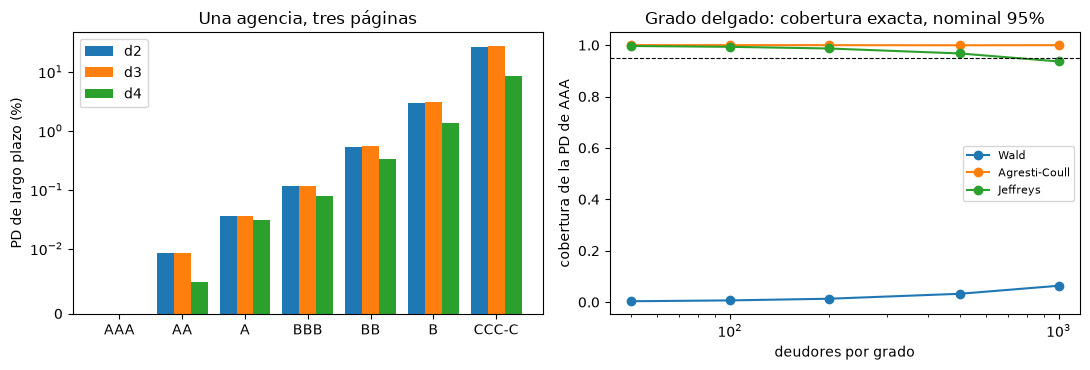

In [9]:
# Dibujar la PD de largo plazo por página y la cobertura de los intervalos de AAA frente al tamaño de muestra
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8))
width = 0.27
for k, d in enumerate(("d2", "d3", "d4")):
    left.bar(np.arange(7) + (k - 1) * width, 100 * lra[d], width, label=d)
left.set_yscale("symlog", linthresh=0.01)
left.set_xticks(range(7))
left.set_xticklabels(grades)
left.set_ylabel("PD de largo plazo (%)")
left.set_title("Una agencia, tres páginas")
left.legend()
sizes = [r["value"] for r in thin_out["rungs"]]
for m, label in methods.items():
    right.plot(sizes, [r["coverage"][m][0] for r in thin_out["rungs"]], marker="o", label=label)
right.axhline(0.95, color="black", linestyle="--", linewidth=0.8)
right.set_xscale("log")
right.set_xlabel("deudores por grado")
right.set_ylabel("cobertura de la PD de AAA")
right.set_title("Grado delgado: cobertura exacta, nominal 95%")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Resultados

- **La definición es parte de la PD.** Bajo la página de incumplimientos la PD de largo plazo de CCC a C es 26,64% y bajo la de transiciones 8,61%, una razón de 0,294; para B es 2,96% frente a 1,33% (0,446), y las razones van de 0,53 (AA) a 0,85 (A) en los grados intermedios. Los eventos de incumplimiento sobre la cohorte de transiciones (`d3`) quedan a menos de 5% de la página de incumplimientos. La diferencia, 18,0 puntos, es 20,6 semianchos del intervalo de Jeffreys de la tasa `d4` (7,23% a 8,97%) y 14,9 errores estándar de la media de sus 26 tasas anuales (1,21 puntos): el muestreo, incluso con la correlación de las tasas anuales con el ciclo, no se le acerca.
- **Mueve el capital.** El ponderador de riesgo corporativo medio de Basilea III de la mezcla de cohortes es 57,97% con las PD de la página de incumplimientos y 47,45% con las de la página de transiciones, 18,1% menos; ambos igualan los valores versionados.
- **Retiros informativos.** Con retiros 10 veces más probables en el año previo al incumplimiento (`k = 9`), quitar las calificaciones retiradas subestima la PD de B en 33,9% (error Monte Carlo 0,8 puntos) y la de CCC a C en 33,1%; mantenerlas sin seguir en 38,1% y 38,5%; seguirlas como pide el párrafo 76 de EBA en 15,2% y 17,7%; la cadena latente no tiene sesgo (+0,8% y +0,1%). En `k = 0` quitar y mantener ya se desvían en +2,4% y -3,6% para B (errores Monte Carlo 1,0 y 0,9 puntos), y el sesgo crece con `k`. La prueba de homogeneidad en el tiempo rechaza de 2,5% a 4% de los conjuntos al 5% en todo peldaño y la prueba del último año de 0% a 1%: ninguna prueba de matriz ve el sesgo.
- **Grados delgados.** Con 50 deudores por grado el intervalo de Wald contiene la PD verdadera de AAA en 0,33% de las muestras (AA 0,25%, A 1,4%) y aún solo en 6,4% con 1.000 deudores (AA 4,8%, A 25,1%); el intervalo de Agresti-Coull la contiene en al menos 99,95% de las muestras para AAA y el de Jeffreys en 99,7% con 50 deudores y 93,6% con 1.000 (nominal 95%). La cobertura exacta del motor iguala el valor versionado.
- **La afirmación.** Los ocho enunciados de la afirmación BS-4 se listan con los valores leídos de los archivos versionados.

Lo que este cuaderno no muestra: que los retiros de CEREP sean informativos (están plantados en la simulación), ni cuál página de CEREP es la definición correcta (la afirmación es que la elección importa y no está en la estimación).

## Resumen

- La PD de largo plazo del grado CCC a C de la misma agencia es 26,64% o 8,61% según la página de CEREP de la que se lea, y el ponderador de riesgo de la mezcla de cohortes se mueve 18%; la definición es parte de la PD y no está en su intervalo de confianza.
- Los retiros informativos subestiman una PD en un tercio cuando se quitan y en cerca de un sexto cuando se siguen, y ninguna prueba de matriz lo ve.
- El intervalo de Wald de un grado delgado casi nunca contiene su PD; el de Jeffreys sí, y el de Agresti-Coull sobrecubre.
- La afirmación BS-4 se enuncia solo hasta donde llegan estos archivos versionados y este cuaderno.

**Qué probar después.** Repite la tabla de retiros para otro grado y mira dónde divergen los tres tratamientos; luego lee el cuaderno 11 sobre las reconciliaciones.

## Referencias

- ESMA, publicación CEREP de calificaciones y transiciones de agencias calificadoras, con su archivo de ayuda ESMA65-8-10634 (secciones 4.2 a 4.4 sobre las páginas y el enunciado sobre la definición de incumplimiento). https://registers.esma.europa.eu/cerep-publication/
- Schuermann, T. y Hanson, S. (2004), Estimating probabilities of default, FRBNY Staff Report 190, nota 4 (retiros) y sección 3 (intervalos). https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr190.pdf
- Brown, L. D., Cai, T. T. y DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- BCBS, Basel Framework, CRE32, enfoque IRB: cálculo de activos ponderados por riesgo. https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- EBA (2017), Guidelines on PD estimation, LGD estimation and the treatment of defaulted exposures, EBA/GL/2017/16, párrafos 73, 76, 84 y 86.